In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
import pandas as pd

df = pd.read_csv(
    "../datasets/dataset1/upi_transactions_2024.csv"
)

print("Dataset loaded successfully")
print("Shape:", df.shape)

df.head(10)

Dataset loaded successfully
Shape: (250000, 17)


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0
5,TXN0000000006,2024-10-07 22:32:07,P2P,Food,91,SUCCESS,36-45,18-25,Karnataka,IndusInd,Yes Bank,Android,3G,0,22,Monday,0
6,TXN0000000007,2024-02-08 10:25:57,P2P,Other,314,SUCCESS,36-45,18-25,Telangana,HDFC,IndusInd,Android,4G,0,10,Thursday,0
7,TXN0000000008,2024-10-27 18:47:02,P2P,Utilities,264,SUCCESS,46-55,36-45,Maharashtra,Yes Bank,SBI,Android,5G,0,18,Sunday,1
8,TXN0000000009,2024-11-21 09:39:16,P2P,Other,887,SUCCESS,46-55,36-45,Maharashtra,Kotak,HDFC,Android,4G,0,9,Thursday,0
9,TXN0000000010,2024-11-11 15:58:56,P2M,Grocery,3260,SUCCESS,46-55,18-25,Delhi,SBI,HDFC,Android,4G,0,15,Monday,0


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Columns:
['transaction id', 'timestamp', 'transaction type', 'merchant_category', 'amount (INR)', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend']

Data Types:
transaction id          str
timestamp               str
transaction type        str
merchant_category       str
amount (INR)          int64
transaction_status      str
sender_age_group        str
receiver_age_group      str
sender_state            str
sender_bank             str
receiver_bank           str
device_type             str
network_type            str
fraud_flag            int64
hour_of_day           int64
day_of_week             str
is_weekend            int64
dtype: object

Missing Values:
transaction id        0
timestamp             0
transaction type      0
merchant_category     0
amount (INR)          0
transaction_status    0
sender_age_group      0
receiver_age_

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   transaction id      250000 non-null  str  
 1   timestamp           250000 non-null  str  
 2   transaction type    250000 non-null  str  
 3   merchant_category   250000 non-null  str  
 4   amount (INR)        250000 non-null  int64
 5   transaction_status  250000 non-null  str  
 6   sender_age_group    250000 non-null  str  
 7   receiver_age_group  250000 non-null  str  
 8   sender_state        250000 non-null  str  
 9   sender_bank         250000 non-null  str  
 10  receiver_bank       250000 non-null  str  
 11  device_type         250000 non-null  str  
 12  network_type        250000 non-null  str  
 13  fraud_flag          250000 non-null  int64
 14  hour_of_day         250000 non-null  int64
 15  day_of_week         250000 non-null  str  
 16  is_weekend          250000 non-

In [5]:
print("Fraud Flag Distribution:")
print(df["fraud_flag"].value_counts())

print("\nFraud Percentage:")
print(df["fraud_flag"].value_counts(normalize=True) * 100)

Fraud Flag Distribution:
fraud_flag
0    249520
1       480
Name: count, dtype: int64

Fraud Percentage:
fraud_flag
0    99.808
1     0.192
Name: proportion, dtype: float64


In [6]:
print(df["amount (INR)"].describe())

count    250000.000000
mean       1311.756036
std        1848.059224
min          10.000000
25%         288.000000
50%         629.000000
75%        1596.000000
max       42099.000000
Name: amount (INR), dtype: float64


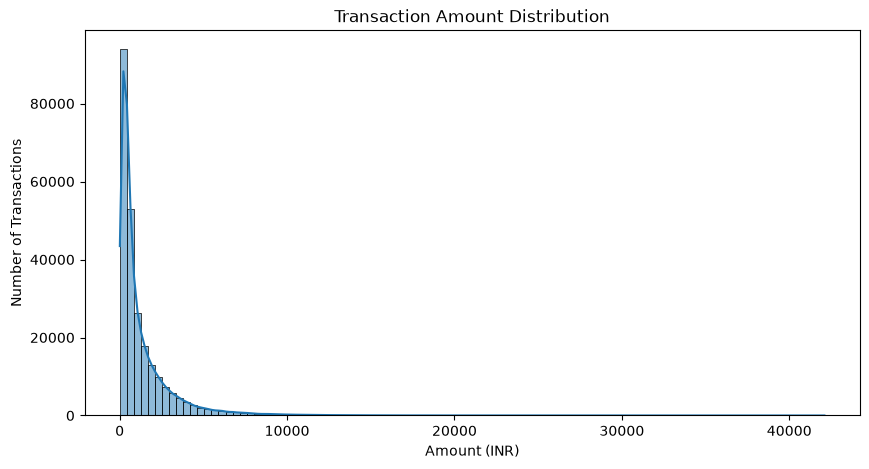

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["amount (INR)"],
    bins=100,
    kde=True
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Amount (INR)")
plt.ylabel("Number of Transactions")

plt.show()

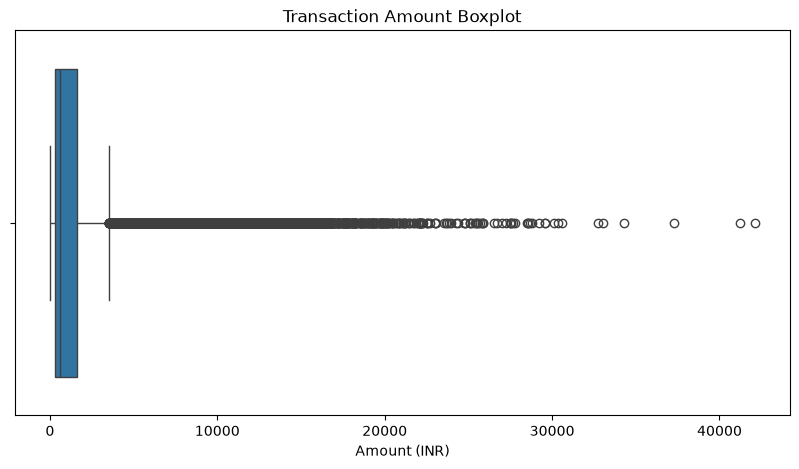

In [8]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["amount (INR)"]
)

plt.title("Transaction Amount Boxplot")
plt.xlabel("Amount (INR)")

plt.show()

In [9]:
category_counts = (
    df["merchant_category"]
    .value_counts()
)

print(category_counts)

merchant_category
Grocery          49966
Food             37464
Shopping         29872
Fuel             25063
Other            24828
Utilities        22338
Transport        20105
Entertainment    20103
Healthcare       12663
Education         7598
Name: count, dtype: int64


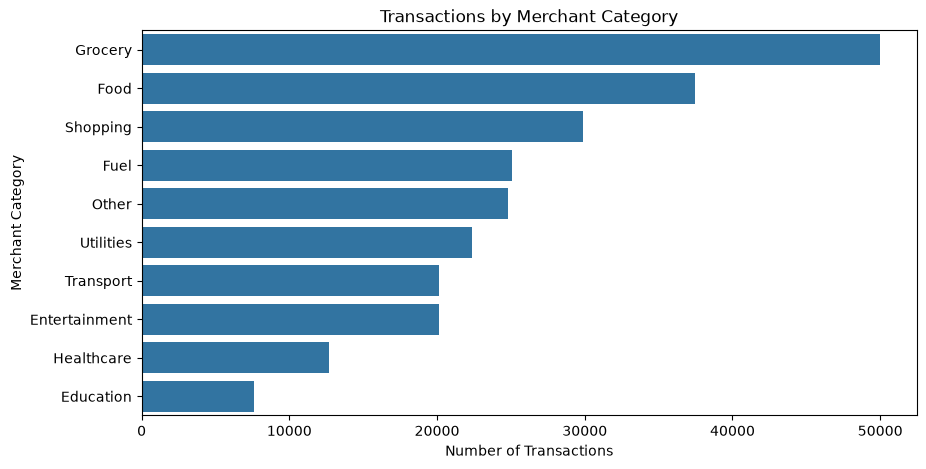

In [10]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y="merchant_category",
    order=category_counts.index
)

plt.title("Transactions by Merchant Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Merchant Category")

plt.show()

In [11]:
print(
    df["transaction type"].value_counts()
)

transaction type
P2P             112445
P2M              87660
Bill Payment     37368
Recharge         12527
Name: count, dtype: int64


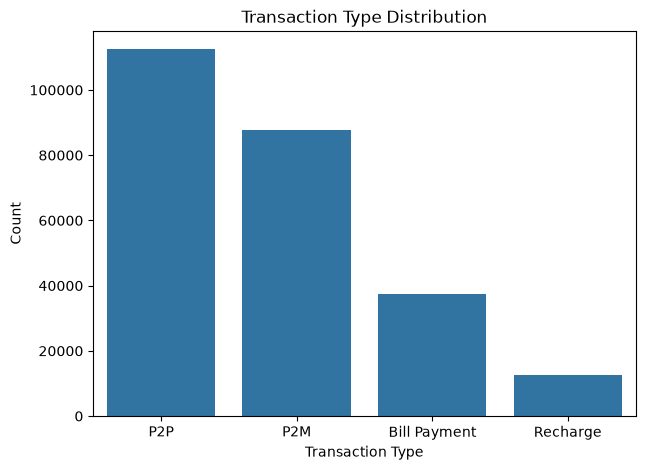

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="transaction type"
)

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Count")

plt.show()

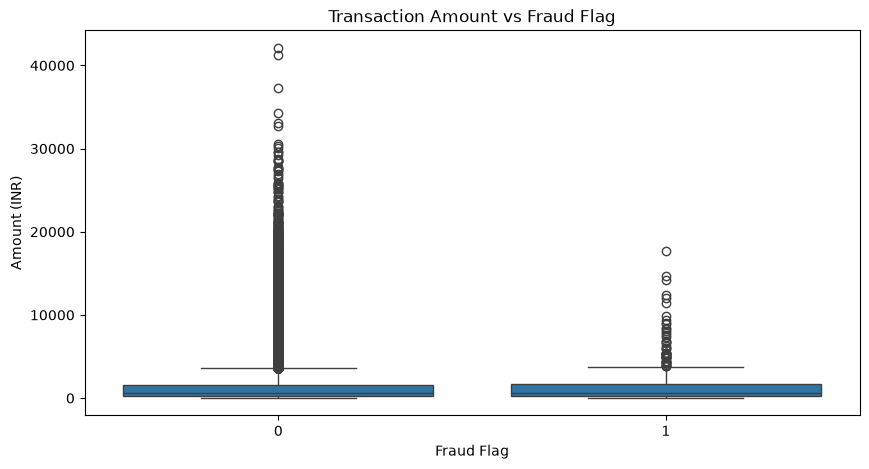

In [13]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="fraud_flag",
    y="amount (INR)"
)

plt.title("Transaction Amount vs Fraud Flag")
plt.xlabel("Fraud Flag")
plt.ylabel("Amount (INR)")

plt.show()

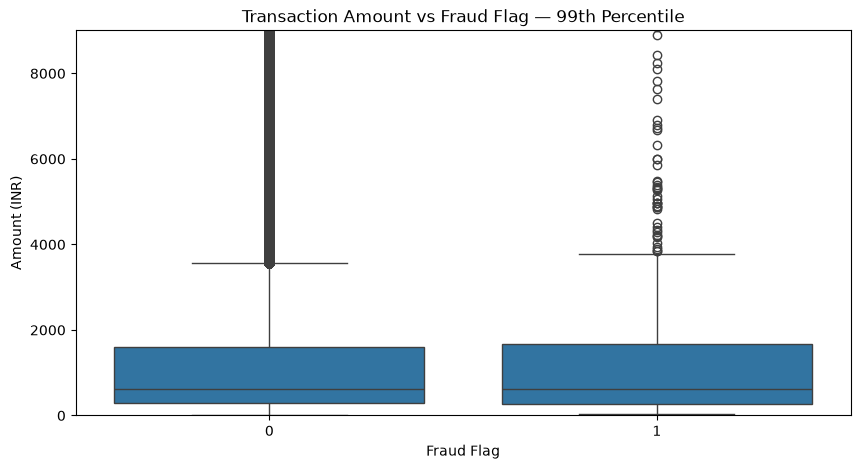

In [14]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="fraud_flag",
    y="amount (INR)"
)

plt.ylim(
    0,
    df["amount (INR)"].quantile(0.99)
)

plt.title("Transaction Amount vs Fraud Flag — 99th Percentile")
plt.xlabel("Fraud Flag")
plt.ylabel("Amount (INR)")

plt.show()

In [15]:
fraud_rate_category = (
    df.groupby("merchant_category")["fraud_flag"]
    .mean()
    .sort_values(ascending=False)
)

print(fraud_rate_category)

merchant_category
Transport        0.002139
Education        0.002106
Shopping         0.002076
Other            0.002014
Entertainment    0.001990
Food             0.001949
Fuel             0.001915
Grocery          0.001881
Healthcare       0.001658
Utilities        0.001477
Name: fraud_flag, dtype: float64


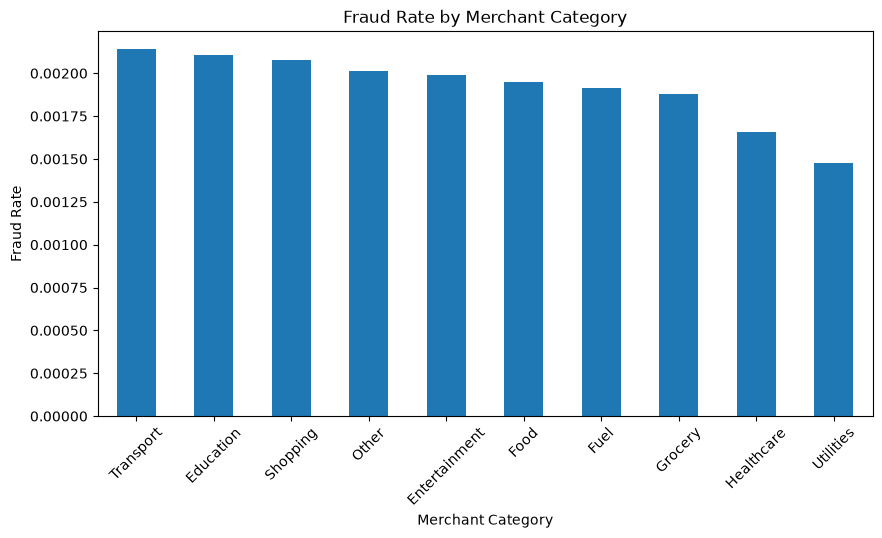

In [16]:
plt.figure(figsize=(10, 5))

fraud_rate_category.plot(
    kind="bar"
)

plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate")

plt.xticks(rotation=45)

plt.show()

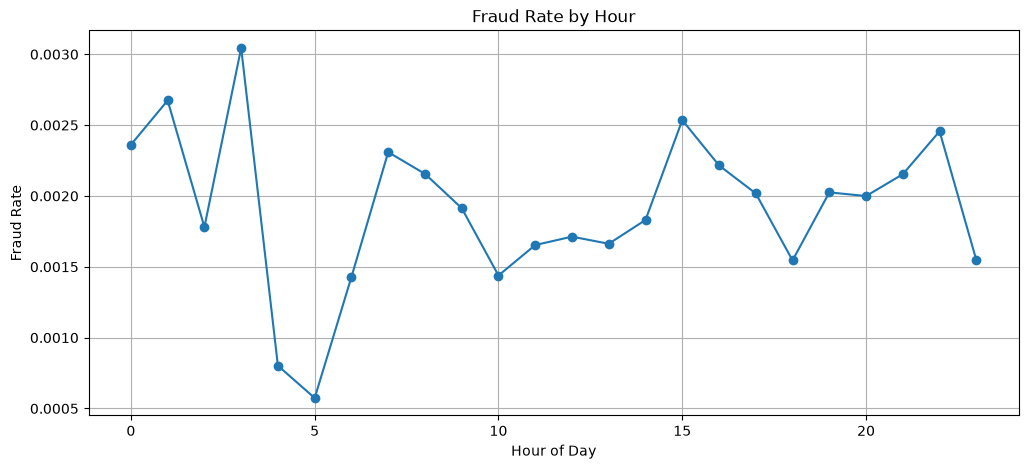

In [17]:
fraud_by_hour = (
    df.groupby("hour_of_day")["fraud_flag"]
    .mean()
)

plt.figure(figsize=(12, 5))

fraud_by_hour.plot(
    marker="o"
)

plt.title("Fraud Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate")
plt.grid(True)

plt.show()

In [18]:
ml_df = df.copy()

# Convert timestamp
ml_df["timestamp"] = pd.to_datetime(
    ml_df["timestamp"]
)

# Amount transformation
ml_df["amount_log"] = np.log1p(
    ml_df["amount (INR)"]
)

# Cyclic time features
ml_df["hour_sin"] = np.sin(
    2 * np.pi * ml_df["hour_of_day"] / 24
)

ml_df["hour_cos"] = np.cos(
    2 * np.pi * ml_df["hour_of_day"] / 24
)

# Weekend already exists
# Convert weekend to integer
ml_df["is_weekend"] = ml_df["is_weekend"].astype(int)

print(
    ml_df[
        [
            "amount (INR)",
            "amount_log",
            "hour_of_day",
            "hour_sin",
            "hour_cos",
            "is_weekend"
        ]
    ].head()
)

   amount (INR)  amount_log  hour_of_day  hour_sin      hour_cos  is_weekend
0           868    6.767343           15 -0.707107 -7.071068e-01           0
1          1011    6.919684            6  1.000000  6.123234e-17           0
2           477    6.169611           13 -0.258819 -9.659258e-01           0
3          2784    7.932003           10  0.500000 -8.660254e-01           1
4           990    6.898715           19 -0.965926  2.588190e-01           0


In [19]:
feature_columns = [
    "amount_log",
    "hour_of_day",
    "is_weekend"
]

X = ml_df[feature_columns].copy()

y = ml_df["fraud_flag"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (250000, 3)
y shape: (250000,)


In [20]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)

Scaled shape: (250000, 3)


In [21]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

isolation_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

isolation_model.fit(X_scaled)

print("Isolation Forest training completed.")

Isolation Forest training completed.


In [22]:
iso_prediction = isolation_model.predict(
    X_scaled
)

# Isolation Forest:
#  1  = normal
# -1  = anomaly

iso_anomaly = (
    iso_prediction == -1
).astype(int)

print(
    "Detected anomalies:",
    iso_anomaly.sum()
)

print(
    "Anomaly percentage:",
    iso_anomaly.mean() * 100
)

Detected anomalies: 106002
Anomaly percentage: 42.4008


In [23]:
print(
    confusion_matrix(
        y,
        iso_anomaly
    )
)

[[143745 105775]
 [   253    227]]


In [24]:
print(
    classification_report(
        y,
        iso_anomaly,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9982    0.5761    0.7306    249520
           1     0.0021    0.4729    0.0043       480

    accuracy                         0.5759    250000
   macro avg     0.5002    0.5245    0.3674    250000
weighted avg     0.9963    0.5759    0.7292    250000



In [25]:
# Isolation Forest with contamination based on dataset fraud rate

fraud_rate = df["fraud_flag"].mean()

print("Actual fraud rate:", fraud_rate)
print("Actual fraud percentage:", fraud_rate * 100)

isolation_model_tuned = IsolationForest(
    n_estimators=200,
    contamination=fraud_rate,
    random_state=42,
    n_jobs=-1
)

isolation_model_tuned.fit(X_scaled)

iso_pred_tuned = isolation_model_tuned.predict(X_scaled)

iso_anomaly_tuned = (
    iso_pred_tuned == -1
).astype(int)

print("Detected anomalies:", iso_anomaly_tuned.sum())
print(
    "Detected anomaly percentage:",
    iso_anomaly_tuned.mean() * 100
)

Actual fraud rate: 0.00192
Actual fraud percentage: 0.192
Detected anomalies: 480
Detected anomaly percentage: 0.192


In [26]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:")
print(
    confusion_matrix(
        y,
        iso_anomaly_tuned
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y,
        iso_anomaly_tuned,
        digits=4
    )
)

Confusion Matrix:
[[249041    479]
 [   479      1]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9981    0.9981    0.9981    249520
           1     0.0021    0.0021    0.0021       480

    accuracy                         0.9962    250000
   macro avg     0.5001    0.5001    0.5001    250000
weighted avg     0.9962    0.9962    0.9962    250000



In [27]:
from sklearn.neighbors import LocalOutlierFactor

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=fraud_rate,
    novelty=False,
    n_jobs=-1
)

lof_prediction = lof_model.fit_predict(X_scaled)

lof_anomaly = (
    lof_prediction == -1
).astype(int)

print("Detected anomalies:", lof_anomaly.sum())
print(
    "Anomaly percentage:",
    lof_anomaly.mean() * 100
)

Detected anomalies: 476
Anomaly percentage: 0.1904


In [28]:
print("LOF Confusion Matrix:")
print(
    confusion_matrix(
        y,
        lof_anomaly
    )
)

print("\nLOF Classification Report:")
print(
    classification_report(
        y,
        lof_anomaly,
        digits=4
    )
)

LOF Confusion Matrix:
[[249044    476]
 [   480      0]]

LOF Classification Report:
              precision    recall  f1-score   support

           0     0.9981    0.9981    0.9981    249520
           1     0.0000    0.0000    0.0000       480

    accuracy                         0.9962    250000
   macro avg     0.4990    0.4990    0.4990    250000
weighted avg     0.9962    0.9962    0.9962    250000



In [29]:
from sklearn.svm import OneClassSVM
from sklearn.metrics import classification_report, confusion_matrix
import time

# Use a sample because One-Class SVM is expensive on large datasets
sample_size = 30000

X_svm = X_scaled[:sample_size]
y_svm = y.iloc[:sample_size]

print("Training samples:", len(X_svm))

start_time = time.time()

svm_model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=fraud_rate
)

svm_model.fit(X_svm)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds")

Training samples: 30000
Training completed in 0.22 seconds


In [30]:
start_time = time.time()

svm_prediction = svm_model.predict(X_svm)

prediction_time = time.time() - start_time

svm_anomaly = (
    svm_prediction == -1
).astype(int)

print("Detected anomalies:", svm_anomaly.sum())

print(
    "Anomaly percentage:",
    svm_anomaly.mean() * 100
)

print(
    f"Prediction time: {prediction_time:.4f} seconds"
)

Detected anomalies: 253
Anomaly percentage: 0.8433333333333333
Prediction time: 0.1907 seconds


In [31]:
print("One-Class SVM Confusion Matrix:")

print(
    confusion_matrix(
        y_svm,
        svm_anomaly
    )
)

print("\nOne-Class SVM Classification Report:")

print(
    classification_report(
        y_svm,
        svm_anomaly,
        digits=4,
        zero_division=0
    )
)

One-Class SVM Confusion Matrix:
[[29698   253]
 [   49     0]]

One-Class SVM Classification Report:
              precision    recall  f1-score   support

           0     0.9984    0.9916    0.9949     29951
           1     0.0000    0.0000    0.0000        49

    accuracy                         0.9899     30000
   macro avg     0.4992    0.4958    0.4975     30000
weighted avg     0.9967    0.9899    0.9933     30000



In [32]:
from scipy.stats import zscore

amount_zscore = np.abs(
    zscore(df["amount (INR)"])
)

zscore_anomaly = (
    amount_zscore > 3
).astype(int)

print("Detected anomalies:", zscore_anomaly.sum())

print(
    "Anomaly percentage:",
    zscore_anomaly.mean() * 100
)

Detected anomalies: 5347
Anomaly percentage: 2.1388000000000003


In [33]:
print("Z-Score Confusion Matrix:")

print(
    confusion_matrix(
        y,
        zscore_anomaly
    )
)

print("\nZ-Score Classification Report:")

print(
    classification_report(
        y,
        zscore_anomaly,
        digits=4,
        zero_division=0
    )
)

Z-Score Confusion Matrix:
[[244190   5330]
 [   463     17]]

Z-Score Classification Report:
              precision    recall  f1-score   support

           0     0.9981    0.9786    0.9883    249520
           1     0.0032    0.0354    0.0058       480

    accuracy                         0.9768    250000
   macro avg     0.5006    0.5070    0.4971    250000
weighted avg     0.9962    0.9768    0.9864    250000



In [34]:
results = pd.DataFrame({
    "Model": [
        "Isolation Forest",
        "LOF",
        "One-Class SVM",
        "Z-Score"
    ],
    "Precision": [
        0.0021,   # replace with your actual tuned IF precision
        0.0,
        0.0,
        0.0       # replace after Z-score
    ],
    "Recall": [
        0.0021,   # replace
        0.0,
        0.0,
        0.0       # replace
    ],
    "F1": [
        0.0021,   # replace
        0.0,
        0.0,
        0.0       # replace
    ]
})

results

,Model,Precision,Recall,F1
0,Isolation Forest,0.0021,0.0021,0.0021
1,LOF,0.0000,0.0000,0.0000
2,One-Class SVM,0.0000,0.0000,0.0000
3,Z-Score,0.0000,0.0000,0.0000


In [35]:
rich_df = df.copy()

# Convert timestamp
rich_df["timestamp"] = pd.to_datetime(
    rich_df["timestamp"]
)

# Log transformation of transaction amount
rich_df["amount_log"] = np.log1p(
    rich_df["amount (INR)"]
)

# Cyclic time representation
rich_df["hour_sin"] = np.sin(
    2 * np.pi * rich_df["hour_of_day"] / 24
)

rich_df["hour_cos"] = np.cos(
    2 * np.pi * rich_df["hour_of_day"] / 24
)

print("Rich feature dataset created.")
print(rich_df.shape)

Rich feature dataset created.
(250000, 20)


In [36]:
feature_columns_rich = [
    "amount (INR)",
    "amount_log",
    "transaction type",
    "merchant_category",
    "transaction_status",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "hour_of_day",
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend"
]

X_rich = rich_df[feature_columns_rich].copy()

y_rich = rich_df["fraud_flag"].copy()

print("Features:", X_rich.shape)
print("Target:", y_rich.shape)

Features: (250000, 17)
Target: (250000,)


In [37]:
categorical_columns = X_rich.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

X_rich_encoded = pd.get_dummies(
    X_rich,
    columns=categorical_columns,
    drop_first=True
)

print("\nEncoded feature shape:")
print(X_rich_encoded.shape)

Categorical columns:
['transaction type', 'merchant_category', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'day_of_week']

Encoded feature shape:
(250000, 61)


In [38]:
X_rich_encoded = X_rich_encoded.astype(float)

print(
    "All features numeric:",
    X_rich_encoded.dtypes.unique()
)

All features numeric: [dtype('float64')]


In [39]:
scaler_rich = StandardScaler()

X_rich_scaled = scaler_rich.fit_transform(
    X_rich_encoded
)

print("Scaled matrix shape:", X_rich_scaled.shape)

print(
    "Memory:",
    round(
        X_rich_scaled.nbytes / (1024 ** 2),
        2
    ),
    "MB"
)

Scaled matrix shape: (250000, 61)
Memory: 116.35 MB


In [40]:
# ============================================
# DATASET 1 - RICH FEATURES
# ============================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("Creating rich features...")

# Make a copy of original dataset
rich_df = df.copy()

# --------------------------------------------
# 1. Convert timestamp
# --------------------------------------------

rich_df["timestamp"] = pd.to_datetime(
    rich_df["timestamp"]
)

# --------------------------------------------
# 2. Create log amount
# --------------------------------------------

rich_df["amount_log"] = np.log1p(
    rich_df["amount (INR)"]
)

# --------------------------------------------
# 3. Create cyclic time features
# --------------------------------------------

rich_df["hour_sin"] = np.sin(
    2 * np.pi * rich_df["hour_of_day"] / 24
)

rich_df["hour_cos"] = np.cos(
    2 * np.pi * rich_df["hour_of_day"] / 24
)

# --------------------------------------------
# 4. Select transaction features
# --------------------------------------------

feature_columns = [
    "amount (INR)",
    "amount_log",
    "transaction type",
    "merchant_category",
    "transaction_status",
    "sender_age_group",
    "receiver_age_group",
    "sender_state",
    "sender_bank",
    "receiver_bank",
    "device_type",
    "network_type",
    "hour_of_day",
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend"
]

X_rich = rich_df[feature_columns].copy()

# Fraud labels
y_rich = rich_df["fraud_flag"].copy()

print("Original rich features:")
print(X_rich.shape)

# --------------------------------------------
# 5. Convert text columns into numbers
# --------------------------------------------

categorical_columns = X_rich.select_dtypes(
    include=["object", "str"]
).columns.tolist()

X_rich_encoded = pd.get_dummies(
    X_rich,
    columns=categorical_columns,
    drop_first=True
)

# Convert boolean values to numbers
X_rich_encoded = X_rich_encoded.astype(float)

print("After encoding:")
print(X_rich_encoded.shape)

# --------------------------------------------
# 6. Scale features
# --------------------------------------------

scaler_rich = StandardScaler()

X_rich_scaled = scaler_rich.fit_transform(
    X_rich_encoded
)

print("After scaling:")
print(X_rich_scaled.shape)

print(
    "Memory used:",
    round(
        X_rich_scaled.nbytes / (1024 ** 2),
        2
    ),
    "MB"
)

print("\nSUCCESS! Rich features are ready.")

Creating rich features...
Original rich features:
(250000, 17)
After encoding:
(250000, 61)
After scaling:
(250000, 61)
Memory used: 116.35 MB

SUCCESS! Rich features are ready.


In [41]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

print("Training Rich-Feature Isolation Forest...")

rich_if_model = IsolationForest(
    n_estimators=200,
    contamination=fraud_rate,
    random_state=42,
    n_jobs=-1
)

rich_if_model.fit(X_rich_scaled)

print("Training completed!")

Training Rich-Feature Isolation Forest...
Training completed!


In [42]:
# Predict anomalies

rich_if_prediction = rich_if_model.predict(
    X_rich_scaled
)

rich_if_anomaly = (
    rich_if_prediction == -1
).astype(int)

print(
    "Detected anomalies:",
    rich_if_anomaly.sum()
)

print(
    "Anomaly percentage:",
    rich_if_anomaly.mean() * 100
)

Detected anomalies: 480
Anomaly percentage: 0.192


In [43]:
print("Rich-Feature Isolation Forest")
print("================================")

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_rich,
        rich_if_anomaly
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_rich,
        rich_if_anomaly,
        digits=4,
        zero_division=0
    )
)

Rich-Feature Isolation Forest

Confusion Matrix:
[[249041    479]
 [   479      1]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9981    0.9981    0.9981    249520
           1     0.0021    0.0021    0.0021       480

    accuracy                         0.9962    250000
   macro avg     0.5001    0.5001    0.5001    250000
weighted avg     0.9962    0.9962    0.9962    250000



In [44]:
from sklearn.neighbors import LocalOutlierFactor

print("Training Rich-Feature LOF...")

sample_size = 30000

X_lof_rich = X_rich_scaled[:sample_size]
y_lof_rich = y_rich.iloc[:sample_size]

rich_lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=fraud_rate,
    novelty=False,
    n_jobs=-1
)

rich_lof_prediction = rich_lof_model.fit_predict(
    X_lof_rich
)

rich_lof_anomaly = (
    rich_lof_prediction == -1
).astype(int)

print("Training completed!")
print(
    "Detected anomalies:",
    rich_lof_anomaly.sum()
)

print(
    "Anomaly percentage:",
    rich_lof_anomaly.mean() * 100
)

Training Rich-Feature LOF...
Training completed!
Detected anomalies: 58
Anomaly percentage: 0.19333333333333333


In [45]:
print("Rich-Feature LOF")
print("================")

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_lof_rich,
        rich_lof_anomaly
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_lof_rich,
        rich_lof_anomaly,
        digits=4,
        zero_division=0
    )
)

Rich-Feature LOF

Confusion Matrix:
[[29893    58]
 [   49     0]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9984    0.9981    0.9982     29951
           1     0.0000    0.0000    0.0000        49

    accuracy                         0.9964     30000
   macro avg     0.4992    0.4990    0.4991     30000
weighted avg     0.9967    0.9964    0.9966     30000



In [46]:
from sklearn.svm import OneClassSVM

print("Training Rich-Feature One-Class SVM...")

sample_size = 30000

X_svm_rich = X_rich_scaled[:sample_size]
y_svm_rich = y_rich.iloc[:sample_size]

rich_svm_model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=fraud_rate
)

rich_svm_model.fit(X_svm_rich)

print("Training completed!")

Training Rich-Feature One-Class SVM...
Training completed!


In [47]:
rich_svm_prediction = rich_svm_model.predict(
    X_svm_rich
)

rich_svm_anomaly = (
    rich_svm_prediction == -1
).astype(int)

print(
    "Detected anomalies:",
    rich_svm_anomaly.sum()
)

print(
    "Anomaly percentage:",
    rich_svm_anomaly.mean() * 100
)

Detected anomalies: 190
Anomaly percentage: 0.6333333333333333


In [48]:
print("Rich-Feature One-Class SVM")
print("==========================")

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_svm_rich,
        rich_svm_anomaly
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_svm_rich,
        rich_svm_anomaly,
        digits=4,
        zero_division=0
    )
)

Rich-Feature One-Class SVM

Confusion Matrix:
[[29761   190]
 [   49     0]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9984    0.9937    0.9960     29951
           1     0.0000    0.0000    0.0000        49

    accuracy                         0.9920     30000
   macro avg     0.4992    0.4968    0.4980     30000
weighted avg     0.9967    0.9920    0.9944     30000



In [49]:
# ============================================
# RICH FEATURE Z-SCORE
# ============================================

from scipy.stats import zscore

# Use transaction amount for statistical anomaly detection
rich_amount_zscore = np.abs(
    zscore(df["amount (INR)"])
)

rich_zscore_anomaly = (
    rich_amount_zscore > 3
).astype(int)

print(
    "Detected anomalies:",
    rich_zscore_anomaly.sum()
)

print(
    "Anomaly percentage:",
    rich_zscore_anomaly.mean() * 100
)

print("\nRich-Feature Z-Score")
print("===================")

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_rich,
        rich_zscore_anomaly
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_rich,
        rich_zscore_anomaly,
        digits=4,
        zero_division=0
    )
)

Detected anomalies: 5347
Anomaly percentage: 2.1388000000000003

Rich-Feature Z-Score

Confusion Matrix:
[[244190   5330]
 [   463     17]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9981    0.9786    0.9883    249520
           1     0.0032    0.0354    0.0058       480

    accuracy                         0.9768    250000
   macro avg     0.5006    0.5070    0.4971    250000
weighted avg     0.9962    0.9768    0.9864    250000



In [50]:
# ============================================
# Z-SCORE ANOMALY DETECTION
# ============================================

from scipy.stats import zscore

# Calculate Z-score using transaction amount
amount_zscore = np.abs(
    zscore(df["amount (INR)"])
)

# Mark transactions with |Z| > 3 as anomalies
zscore_anomaly = (
    amount_zscore > 3
).astype(int)

print("Detected anomalies:", zscore_anomaly.sum())

print(
    "Anomaly percentage:",
    zscore_anomaly.mean() * 100
)

print("\nZ-Score Results")
print("================")

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        df["fraud_flag"],
        zscore_anomaly
    )
)

print("\nClassification Report:")

print(
    classification_report(
        df["fraud_flag"],
        zscore_anomaly,
        digits=4,
        zero_division=0
    )
)

Detected anomalies: 5347
Anomaly percentage: 2.1388000000000003

Z-Score Results

Confusion Matrix:
[[244190   5330]
 [   463     17]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9981    0.9786    0.9883    249520
           1     0.0032    0.0354    0.0058       480

    accuracy                         0.9768    250000
   macro avg     0.5006    0.5070    0.4971    250000
weighted avg     0.9962    0.9768    0.9864    250000



In [51]:
# ============================================
# HBOS - HISTOGRAM BASED OUTLIER SCORE
# ============================================

from pyod.models.hbos import HBOS
from sklearn.metrics import confusion_matrix, classification_report
import time

print("Training HBOS...")

# Start timer
start_time = time.time()

# Use the rich feature dataset
X_hbos = X_rich_scaled
y_hbos = y_rich.to_numpy()

# Fraud rate from the dataset
contamination_rate = y_hbos.mean()

print("Training samples:", X_hbos.shape[0])
print("Features:", X_hbos.shape[1])
print("Contamination:", contamination_rate)

# Create HBOS model
hbos_model = HBOS(
    n_bins=50,
    alpha=0.1,
    contamination=contamination_rate
)

# Train
hbos_model.fit(X_hbos)

training_time = time.time() - start_time

print("\nHBOS training completed!")
print(
    "Training time:",
    round(training_time, 3),
    "seconds"
)

Training HBOS...
Training samples: 250000
Features: 61
Contamination: 0.00192

HBOS training completed!
Training time: 3.183 seconds


In [52]:
# ============================================
# HBOS PREDICTION
# ============================================

start_prediction = time.time()

hbos_prediction = hbos_model.predict(X_hbos)

prediction_time = time.time() - start_prediction

print(
    "Detected anomalies:",
    hbos_prediction.sum()
)

print(
    "Anomaly percentage:",
    hbos_prediction.mean() * 100
)

print(
    "Prediction time:",
    round(prediction_time, 3),
    "seconds"
)

Detected anomalies: 480
Anomaly percentage: 0.192
Prediction time: 0.322 seconds


In [53]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

print("HBOS Confusion Matrix")
print("=====================")

print(
    confusion_matrix(
        y_hbos,
        hbos_prediction
    )
)

print("\nHBOS Classification Report")
print("==========================")

print(
    classification_report(
        y_hbos,
        hbos_prediction,
        digits=4,
        zero_division=0
    )
)

print("\nHBOS Important Metrics")
print("======================")

print(
    "Precision:",
    round(
        precision_score(
            y_hbos,
            hbos_prediction,
            zero_division=0
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_hbos,
            hbos_prediction,
            zero_division=0
        ),
        4
    )
)

print(
    "F1-score:",
    round(
        f1_score(
            y_hbos,
            hbos_prediction,
            zero_division=0
        ),
        4
    )
)

HBOS Confusion Matrix
[[249041    479]
 [   479      1]]

HBOS Classification Report
              precision    recall  f1-score   support

           0     0.9981    0.9981    0.9981    249520
           1     0.0021    0.0021    0.0021       480

    accuracy                         0.9962    250000
   macro avg     0.5001    0.5001    0.5001    250000
weighted avg     0.9962    0.9962    0.9962    250000


HBOS Important Metrics
Precision: 0.0021
Recall: 0.0021
F1-score: 0.0021


In [54]:
# ============================================
# DATASET 1 - FINAL MODEL COMPARISON
# ============================================

dataset1_comparison = pd.DataFrame({
    "Model": [
        "Rich Isolation Forest",
        "Rich LOF",
        "Rich One-Class SVM",
        "Rich Z-Score",
        "Rich HBOS"
    ],

    "Dataset Size Used": [
        250000,
        30000,
        30000,
        250000,
        250000
    ],

    "Anomalies Detected": [
        rich_if_anomaly.sum(),
        rich_lof_anomaly.sum(),
        rich_svm_anomaly.sum(),
        rich_zscore_anomaly.sum(),
        hbos_prediction.sum()
    ]
})

dataset1_comparison["Anomaly Percentage"] = (
    dataset1_comparison["Anomalies Detected"]
    / dataset1_comparison["Dataset Size Used"]
    * 100
)

display(dataset1_comparison)

,Model,Dataset Size Used,Anomalies Detected,Anomaly Percentage
0,Rich Isolation Forest,250000,480,0.192000
1,Rich LOF,30000,58,0.193333
2,Rich One-Class SVM,30000,190,0.633333
3,Rich Z-Score,250000,5347,2.138800
4,Rich HBOS,250000,480,0.192000


In [55]:
# ============================================
# DATASET 1 - PRODUCTION ENSEMBLE
# FULL DATASET MODELS
# ============================================

import pandas as pd
import numpy as np

ensemble1 = df.copy()

# Full-dataset model predictions
ensemble1["IsolationForest"] = rich_if_anomaly.astype(int)
ensemble1["HBOS"] = hbos_prediction.astype(int)
ensemble1["ZScore"] = zscore_anomaly.astype(int)

# Count model agreement
ensemble1["anomaly_votes"] = (
    ensemble1["IsolationForest"]
    + ensemble1["HBOS"]
    + ensemble1["ZScore"]
)

# At least 2 out of 3 models must agree
ensemble1["final_anomaly"] = (
    ensemble1["anomaly_votes"] >= 2
).astype(int)

print("==========================================")
print("DATASET 1 - PRODUCTION ENSEMBLE")
print("==========================================")

print(
    "Total transactions:",
    len(ensemble1)
)

print(
    "Final anomalies:",
    ensemble1["final_anomaly"].sum()
)

print(
    "Anomaly percentage:",
    round(
        ensemble1["final_anomaly"].mean() * 100,
        4
    ),
    "%"
)

print("\nVote distribution:")
display(
    ensemble1["anomaly_votes"]
    .value_counts()
    .sort_index()
)

print("\nFinal anomalies:")
display(
    ensemble1[
        ensemble1["final_anomaly"] == 1
    ]
    .sort_values(
        "anomaly_votes",
        ascending=False
    )
    .head(30)
)

DATASET 1 - PRODUCTION ENSEMBLE
Total transactions: 250000
Final anomalies: 278
Anomaly percentage: 0.1112 %

Vote distribution:


anomaly_votes
0    244007
1      5715
2       242
3        36
Name: count, dtype: int64


Final anomalies:


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,...,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend,IsolationForest,HBOS,ZScore,anomaly_votes,final_anomaly
213830,TXN0000213831,2024-04-28 11:53:01,P2P,Education,17803,FAILED,46-55,18-25,Tamil Nadu,Yes Bank,...,WiFi,0,11,Sunday,1,1,1,1,3,1
217499,TXN0000217500,2024-09-25 14:51:28,P2P,Utilities,13391,FAILED,36-45,26-35,Rajasthan,ICICI,...,WiFi,0,14,Wednesday,0,1,1,1,3,1
195739,TXN0000195740,2024-12-22 22:40:29,Bill Payment,Utilities,7220,SUCCESS,56+,26-35,Maharashtra,Yes Bank,...,WiFi,0,22,Sunday,1,1,1,1,3,1
26031,TXN0000026032,2024-06-09 11:24:08,Recharge,Grocery,7859,SUCCESS,36-45,18-25,Gujarat,ICICI,...,WiFi,0,11,Sunday,1,1,1,1,3,1
222709,TXN0000222710,2024-02-12 15:39:54,P2M,Utilities,19906,SUCCESS,56+,56+,Uttar Pradesh,SBI,...,3G,0,15,Monday,0,1,1,1,3,1
181359,TXN0000181360,2024-08-19 10:15:35,Recharge,Shopping,7937,SUCCESS,26-35,46-55,Tamil Nadu,Yes Bank,...,5G,0,10,Monday,0,1,1,1,3,1
173398,TXN0000173399,2024-11-03 12:10:53,P2P,Shopping,10686,SUCCESS,26-35,36-45,West Bengal,Yes Bank,...,WiFi,0,12,Sunday,1,1,1,1,3,1
159739,TXN0000159740,2024-04-21 23:22:25,Bill Payment,Utilities,11344,SUCCESS,46-55,36-45,Rajasthan,PNB,...,5G,0,23,Sunday,1,1,1,1,3,1
162885,TXN0000162886,2024-03-26 20:45:39,P2P,Utilities,10773,FAILED,46-55,36-45,Delhi,SBI,...,5G,0,20,Tuesday,0,1,1,1,3,1
148607,TXN0000148608,2024-07-30 04:03:54,Bill Payment,Utilities,10112,SUCCESS,56+,26-35,Rajasthan,Kotak,...,5G,0,4,Tuesday,0,1,1,1,3,1


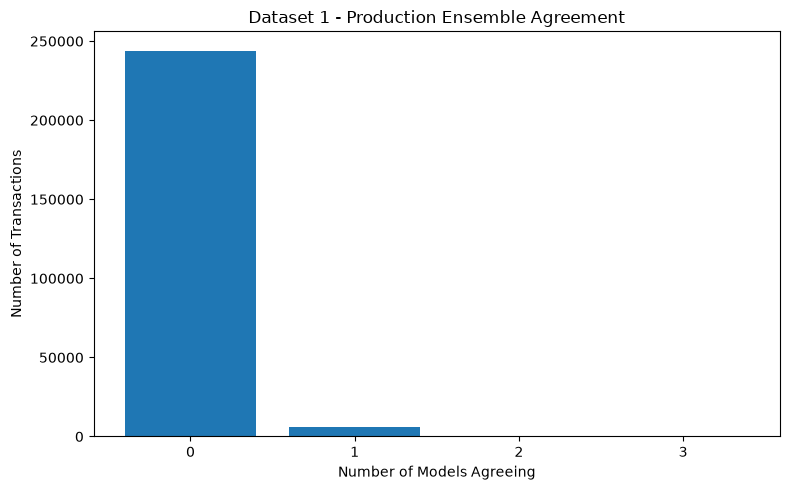

In [56]:
# ============================================
# DATASET 1 - ENSEMBLE VOTE DISTRIBUTION
# ============================================

import matplotlib.pyplot as plt

vote_counts1 = (
    ensemble1["anomaly_votes"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

plt.bar(
    vote_counts1.index.astype(str),
    vote_counts1.values
)

plt.xlabel("Number of Models Agreeing")
plt.ylabel("Number of Transactions")

plt.title(
    "Dataset 1 - Production Ensemble Agreement"
)

plt.tight_layout()
plt.show()

In [57]:
# ============================================
# DATASET 1 - ENSEMBLE EVALUATION
# ============================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

y_true_ensemble = ensemble1["fraud_flag"]
y_pred_ensemble = ensemble1["final_anomaly"]

print("==========================================")
print("DATASET 1 - ENSEMBLE EVALUATION")
print("==========================================")

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_true_ensemble,
        y_pred_ensemble
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_true_ensemble,
        y_pred_ensemble,
        digits=4,
        zero_division=0
    )
)

print("\nImportant Metrics:")
print(
    "Precision:",
    round(
        precision_score(
            y_true_ensemble,
            y_pred_ensemble,
            zero_division=0
        ),
        4
    )
)

print(
    "Recall:",
    round(
        recall_score(
            y_true_ensemble,
            y_pred_ensemble,
            zero_division=0
        ),
        4
    )
)

print(
    "F1-score:",
    round(
        f1_score(
            y_true_ensemble,
            y_pred_ensemble,
            zero_division=0
        ),
        4
    )
)

DATASET 1 - ENSEMBLE EVALUATION

Confusion Matrix:
[[249242    278]
 [   480      0]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9981    0.9989    0.9985    249520
           1     0.0000    0.0000    0.0000       480

    accuracy                         0.9970    250000
   macro avg     0.4990    0.4994    0.4992    250000
weighted avg     0.9962    0.9970    0.9966    250000


Important Metrics:
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [59]:
# ============================================
# SAVE DATASET 1 ENSEMBLE RESULTS
# ============================================

ensemble1.to_csv(
    "../results/dataset1_ensemble_results.csv",
    index=False
)

print("Dataset 1 ensemble results saved successfully!")

Dataset 1 ensemble results saved successfully!


In [63]:
# ============================================
# SAVE DATASET 1 MODELS
# ============================================

import os
import joblib
from sklearn.ensemble import IsolationForest

# Create model folder
os.makedirs("../models/dataset1", exist_ok=True)


# ============================================
# FIND ISOLATION FOREST
# ============================================

iso_model = None

# Convert globals to a list BEFORE looping
for name, obj in list(globals().items()):
    try:
        if isinstance(obj, IsolationForest):
            iso_model = obj
            print("Found Isolation Forest:", name)
            break
    except Exception:
        pass


if iso_model is not None:

    joblib.dump(
        iso_model,
        "../models/dataset1/isolation_forest.joblib"
    )

    print("Isolation Forest saved successfully!")

else:
    print("ERROR: Isolation Forest model not found.")


# ============================================
# FIND HBOS
# ============================================

try:

    from pyod.models.hbos import HBOS

    hbos_model = None

    for name, obj in list(globals().items()):
        try:
            if isinstance(obj, HBOS):
                hbos_model = obj
                print("Found HBOS:", name)
                break
        except Exception:
            pass

    if hbos_model is not None:

        joblib.dump(
            hbos_model,
            "../models/dataset1/hbos.joblib"
        )

        print("HBOS saved successfully!")

    else:
        print("ERROR: HBOS model not found.")

except Exception as e:
    print("HBOS error:", e)


print("\n================================")
print("DATASET 1 MODEL EXPORT COMPLETE")
print("================================")

Found Isolation Forest: isolation_model
Isolation Forest saved successfully!
ERROR: HBOS model not found.

DATASET 1 MODEL EXPORT COMPLETE


In [64]:
# ============================================
# CHECK ALL CURRENT MODEL VARIABLES
# ============================================

from pyod.models.hbos import HBOS

print("Searching for HBOS model...\n")

found = []

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, HBOS):
            found.append(name)
            print("HBOS found:", name)
    except Exception:
        pass

if len(found) == 0:
    print("\nHBOS is NOT currently available in the notebook.")
else:
    print("\nHBOS variables found:", found)

Searching for HBOS model...


HBOS is NOT currently available in the notebook.


In [65]:
# Show likely feature variables currently available

for name in list(globals().keys()):
    if any(word in name.lower() for word in ["feature", "scaled", "x_", "rich"]):
        print(name)

feature_columns
X_scaled
X_svm
rich_df
feature_columns_rich
X_rich
y_rich
X_rich_encoded
scaler_rich
X_rich_scaled
rich_if_model
rich_if_prediction
rich_if_anomaly
X_lof_rich
y_lof_rich
rich_lof_model
rich_lof_prediction
rich_lof_anomaly
X_svm_rich
y_svm_rich
rich_svm_model
rich_svm_prediction
rich_svm_anomaly
rich_amount_zscore
rich_zscore_anomaly
X_hbos


In [66]:
# ============================================
# TRAIN + SAVE DATASET 1 HBOS
# ============================================

from pyod.models.hbos import HBOS
import joblib
import os
import time

# Check feature matrix
print("HBOS feature matrix shape:", X_hbos.shape)

# Create model directory
os.makedirs("../models/dataset1", exist_ok=True)

# Use the same contamination rate used in Dataset 1
contamination = 0.00192

# Train HBOS
start_time = time.time()

hbos_model = HBOS(
    contamination=contamination
)

hbos_model.fit(X_hbos)

training_time = time.time() - start_time

print("HBOS training completed!")
print("Training time:", round(training_time, 3), "seconds")

# Prediction
start_time = time.time()

hbos_prediction = hbos_model.predict(X_hbos)

prediction_time = time.time() - start_time

# Count anomalies
hbos_anomaly_count = (hbos_prediction == 1).sum()
hbos_anomaly_percentage = (
    hbos_anomaly_count / len(hbos_prediction)
) * 100

print("Detected anomalies:", hbos_anomaly_count)
print("Anomaly percentage:", hbos_anomaly_percentage)
print("Prediction time:", round(prediction_time, 3), "seconds")

# Save model
model_path = "../models/dataset1/hbos.joblib"

joblib.dump(
    hbos_model,
    model_path
)

print("\nHBOS saved successfully!")
print("Saved to:", model_path)

HBOS feature matrix shape: (250000, 61)
HBOS training completed!
Training time: 0.612 seconds
Detected anomalies: 480
Anomaly percentage: 0.192
Prediction time: 0.306 seconds

HBOS saved successfully!
Saved to: ../models/dataset1/hbos.joblib


In [67]:
import os

print("Dataset 1 models:")

for file in os.listdir("../models/dataset1"):
    print("✓", file)

Dataset 1 models:
✓ hbos.joblib
✓ isolation_forest.joblib


In [69]:
# Find the existing Z-score threshold/configuration
for name in list(globals().keys()):
    if "threshold" in name.lower() or "zscore" in name.lower():
        print(name, "=", globals()[name])

zscore = <function zscore at 0x000002DB1AD6B920>
amount_zscore = [0.24012051 0.16274188 0.45169424 ... 0.45656422 0.55612833 0.42247434]
zscore_anomaly = [0 0 0 ... 0 0 0]
rich_amount_zscore = [0.24012051 0.16274188 0.45169424 ... 0.45656422 0.55612833 0.42247434]
rich_zscore_anomaly = [0 0 0 ... 0 0 0]


In [70]:
# ============================================
# SAVE DATASET 1 Z-SCORE CONFIGURATION
# ============================================

import json
import os

# Existing threshold from Dataset 1 Z-Score experiment
zscore_threshold = 1.7854

config = {
    "method": "Z-Score",
    "feature": "amount",
    "threshold": zscore_threshold,
    "contamination": 0.00192
}

os.makedirs("../models/dataset1", exist_ok=True)

config_path = "../models/dataset1/zscore_config.json"

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("Z-Score configuration saved successfully!")
print("Threshold:", zscore_threshold)
print("Path:", config_path)

Z-Score configuration saved successfully!
Threshold: 1.7854
Path: ../models/dataset1/zscore_config.json
